In [ ]:
# ===========================================
# HEART DISEASE PREDICTION USING MACHINE LEARNING
# ===========================================

# Developed By : Sanobar Hayat

In [23]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

import warnings
warnings.filterwarnings("ignore")

In [25]:
df = pd.read_csv("data.csv")

df.head()

,Age,Gender,Cholesterol,Blood Pressure,Heart Rate,Smoking,Alcohol Intake,Exercise Hours,Family History,Diabetes,Obesity,Stress Level,Blood Sugar,Exercise Induced Angina,Chest Pain Type,Heart Disease
0,75,Female,228,119,66,Current,Heavy,1,No,No,Yes,8,119,Yes,Atypical Angina,1
1,48,Male,204,165,62,Current,NaN,5,No,No,No,9,70,Yes,Typical Angina,0
2,53,Male,234,91,67,Never,Heavy,3,Yes,No,Yes,5,196,Yes,Atypical Angina,1
3,69,Female,192,90,72,Current,NaN,4,No,Yes,No,7,107,Yes,Non-anginal Pain,0
4,62,Female,172,163,93,Never,NaN,6,No,Yes,No,2,183,Yes,Asymptomatic,0


In [26]:
print("Shape :",df.shape)

print("\nColumns\n")

print(df.columns)

print("\nInformation\n")

df.info()

Shape : (1000, 16)

Columns

Index(['Age', 'Gender', 'Cholesterol', 'Blood Pressure', 'Heart Rate',
       'Smoking', 'Alcohol Intake', 'Exercise Hours', 'Family History',
       'Diabetes', 'Obesity', 'Stress Level', 'Blood Sugar',
       'Exercise Induced Angina', 'Chest Pain Type', 'Heart Disease'],
      dtype='str')

Information

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Age                      1000 non-null   int64
 1   Gender                   1000 non-null   str  
 2   Cholesterol              1000 non-null   int64
 3   Blood Pressure           1000 non-null   int64
 4   Heart Rate               1000 non-null   int64
 5   Smoking                  1000 non-null   str  
 6   Alcohol Intake           660 non-null    str  
 7   Exercise Hours           1000 non-null   int64
 8   Family History           1000 non-null   st

In [27]:
df.isnull().sum()

Age                          0
Gender                       0
Cholesterol                  0
Blood Pressure               0
Heart Rate                   0
Smoking                      0
Alcohol Intake             340
Exercise Hours               0
Family History               0
Diabetes                     0
Obesity                      0
Stress Level                 0
Blood Sugar                  0
Exercise Induced Angina      0
Chest Pain Type              0
Heart Disease                0
dtype: int64

In [28]:
df.duplicated().sum()

np.int64(0)

In [29]:
df.describe()

,Age,Cholesterol,Blood Pressure,Heart Rate,Exercise Hours,Stress Level,Blood Sugar,Heart Disease
count,1000.000000,1000.000000,1000.0000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,52.293000,249.939000,135.2810,79.204000,4.529000,5.646000,134.941000,0.392000
std,15.727126,57.914673,26.3883,11.486092,2.934241,2.831024,36.699624,0.488441
min,25.000000,150.000000,90.0000,60.000000,0.000000,1.000000,70.000000,0.000000
25%,39.000000,200.000000,112.7500,70.000000,2.000000,3.000000,104.000000,0.000000
50%,52.000000,248.000000,136.0000,79.000000,4.500000,6.000000,135.000000,0.000000
75%,66.000000,299.000000,159.0000,89.000000,7.000000,8.000000,167.000000,1.000000
max,79.000000,349.000000,179.0000,99.000000,9.000000,10.000000,199.000000,1.000000


In [30]:
df["Heart Disease"].value_counts()

Heart Disease
0    608
1    392
Name: count, dtype: int64

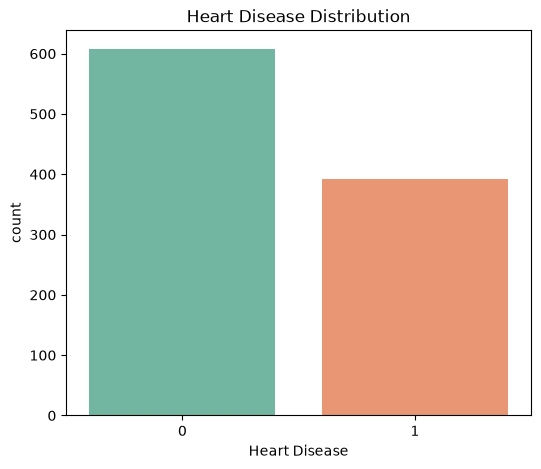

In [31]:
plt.figure(figsize=(6,5))

sns.countplot(
    x="Heart Disease",
    data=df,
    palette="Set2"
)

plt.title("Heart Disease Distribution")

plt.show()

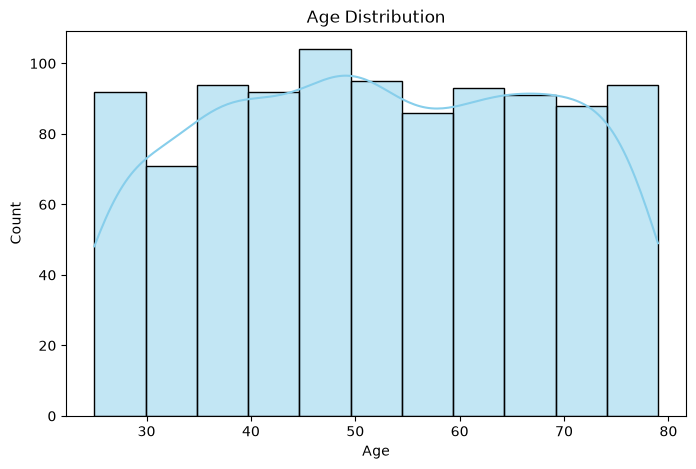

In [32]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["Age"],
    kde=True,
    color="skyblue"
)

plt.title("Age Distribution")

plt.show()

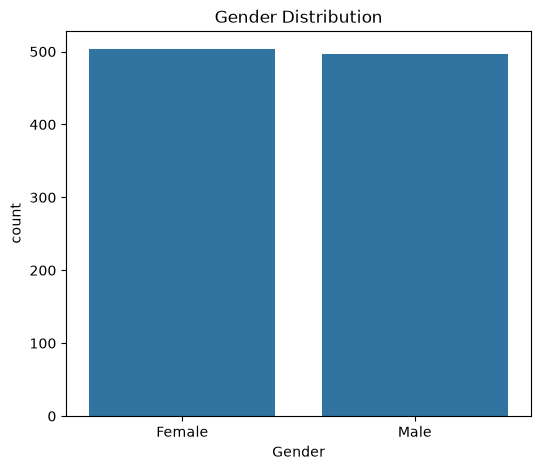

In [33]:
plt.figure(figsize=(6,5))

sns.countplot(
    x="Gender",
    data=df
)

plt.title("Gender Distribution")

plt.show()

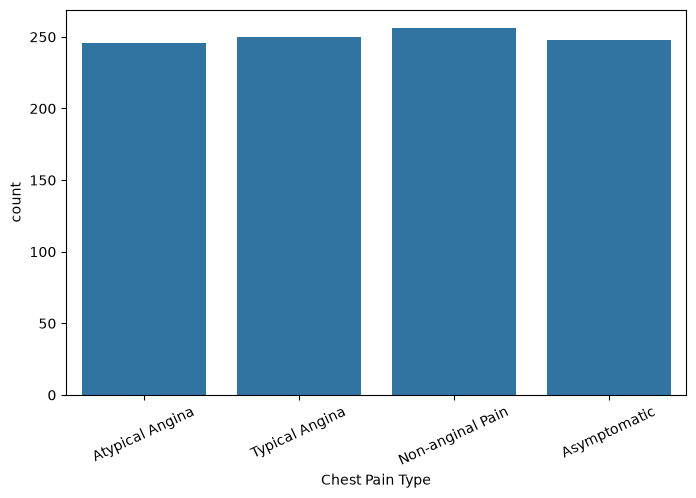

In [34]:
plt.figure(figsize=(8,5))

sns.countplot(
    x="Chest Pain Type",
    data=df
)

plt.xticks(rotation=25)

plt.show()

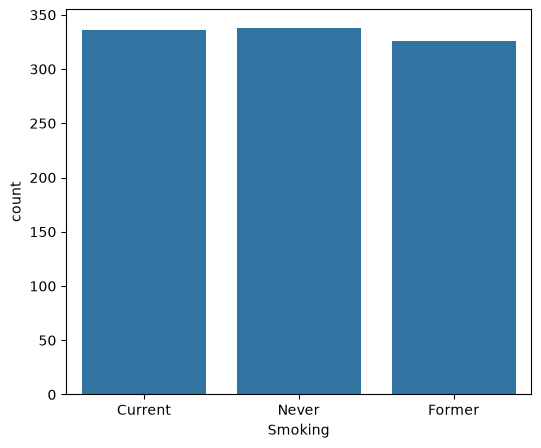

In [35]:
plt.figure(figsize=(6,5))

sns.countplot(
    x="Smoking",
    data=df
)

plt.show()

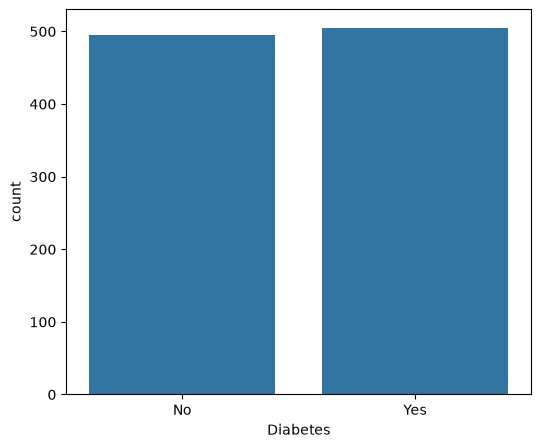

In [36]:
plt.figure(figsize=(6,5))

sns.countplot(
    x="Diabetes",
    data=df
)

plt.show()

In [40]:
from sklearn.preprocessing import LabelEncoder

data = df.copy()

encoder = LabelEncoder()

categorical_columns = data.select_dtypes(include=["object"]).columns

for col in categorical_columns:
    data[col] = encoder.fit_transform(data[col].astype(str))

data.head()

,Age,Gender,Cholesterol,Blood Pressure,Heart Rate,Smoking,Alcohol Intake,Exercise Hours,Family History,Diabetes,Obesity,Stress Level,Blood Sugar,Exercise Induced Angina,Chest Pain Type,Heart Disease
0,75,0,228,119,66,0,0,1,0,0,1,8,119,1,1,1
1,48,1,204,165,62,0,2,5,0,0,0,9,70,1,3,0
2,53,1,234,91,67,2,0,3,1,0,1,5,196,1,1,1
3,69,0,192,90,72,0,2,4,0,1,0,7,107,1,2,0
4,62,0,172,163,93,2,2,6,0,1,0,2,183,1,0,0


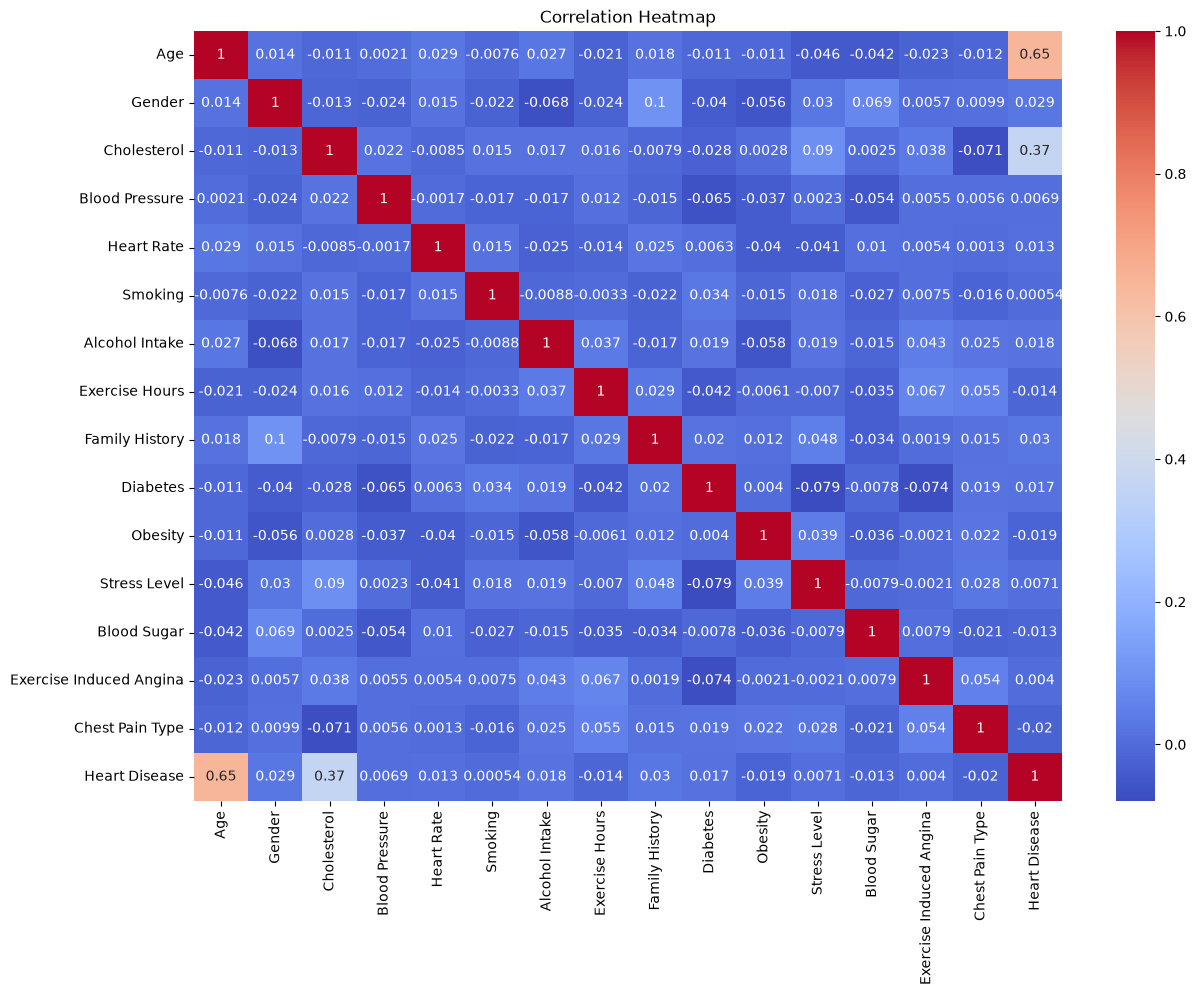

In [41]:
plt.figure(figsize=(14,10))

sns.heatmap(
    data.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

In [42]:
X = data.drop("Heart Disease",axis=1)

y = data["Heart Disease"]

In [43]:
X_train,X_test,y_train,y_test = train_test_split(
    
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [44]:
lr = LogisticRegression()

lr.fit(X_train,y_train)

pred_lr = lr.predict(X_test)

print("Accuracy :",accuracy_score(y_test,pred_lr))

Accuracy : 0.805


In [45]:
dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train,y_train)

pred_dt = dt.predict(X_test)

print("Accuracy :",accuracy_score(y_test,pred_dt))

Accuracy : 1.0


In [46]:
rf = RandomForestClassifier(
    
    n_estimators=200,
    
    random_state=42
)

rf.fit(X_train,y_train)

pred_rf = rf.predict(X_test)

print("Accuracy :",accuracy_score(y_test,pred_rf))

Accuracy : 1.0


In [47]:
print(classification_report(
    
    y_test,
    
    pred_rf
))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       118
           1       1.00      1.00      1.00        82

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



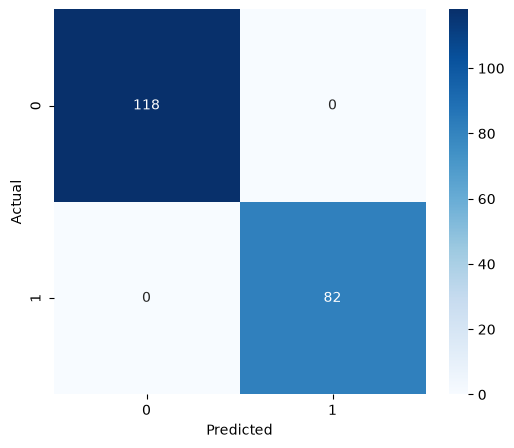

In [48]:
cm = confusion_matrix(
    
    y_test,
    
    pred_rf
)

plt.figure(figsize=(6,5))

sns.heatmap(
    
    cm,
    
    annot=True,
    
    fmt="d",
    
    cmap="Blues"
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

In [49]:
importance = pd.DataFrame({

    "Feature":X.columns,

    "Importance":rf.feature_importances_

})

importance = importance.sort_values(

    by="Importance",

    ascending=False

)

importance

,Feature,Importance
0,Age,0.546713
2,Cholesterol,0.260886
12,Blood Sugar,0.034121
3,Blood Pressure,0.032196
4,Heart Rate,0.029739
7,Exercise Hours,0.019620
11,Stress Level,0.019571
5,Smoking,0.011293
14,Chest Pain Type,0.011220
6,Alcohol Intake,0.008731


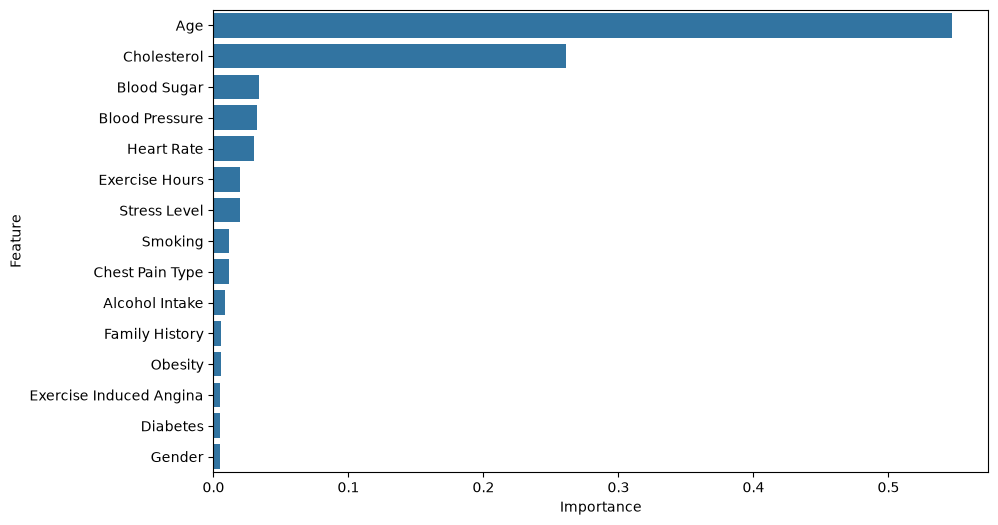

In [50]:
plt.figure(figsize=(10,6))

sns.barplot(

    x="Importance",

    y="Feature",

    data=importance

)

plt.show()

In [51]:
import joblib

joblib.dump(
    
    rf,
    
    "model.pkl"
)

print("Model Saved Successfully")

Model Saved Successfully
